# Imputing missing FISH coordinates

Chromatin tracing misses loci: a probe is too dim, two spots overlap, a hybridisation round
fails.  Typically 5–30 % of the (trace, locus) positions have no coordinate, either as NaN rows
or as absent rows.  `uchrom.im.impute.impute_coordinates` fills them with one of three
methods: **linear** or **cubic** interpolation along the genomic coordinate of each trace, or
**SnapFISH-IMPUTE** (Yu et al., [github.com/hyuyu104/SnapFISH-IMPUTE](https://github.com/hyuyu104/SnapFISH-IMPUTE)),
which borrows the missing pairwise distances from the most similar other traces and
recovers 3-D positions that fit them.  You will run all three, see how absent rows and the
locus panel are handled, and then measure on held-out real spots how close each method gets.

**Data**: ORCA tracing of the *Sox2* locus in 129 × CAST mouse ES cells at 5 kb (Huang et al.
2021, *Nature Genetics*, doi:10.1038/s41588-021-00863-6) as distributed with SnapFISH-IMPUTE:
`ds.fetch("huang2021_sox2")` downloads its coordinate and locus tables once from GitHub (7 MB);
we use the first 5 traces × 41 loci of the 129 allele.  For the accuracy test, 300 IMR90 chr21
traces of Bintu et al. 2018, *Science* (65 loci × 30 kb; `ds.fetch("bintu_imr90")` downloads the
authors' CSV from GitHub, 2 MB).  **Runtime**: about 2 minutes.

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from chromdata import ChromData
import uchrom.datasets as ds
from uchrom.im.impute import impute_coordinates

plt.rcParams["figure.dpi"] = 90
# SnapFISH's NaN-aware numerics (Box-Cox on masked distance matrices) emit harmless warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)
SOX2 = ds.fetch("huang2021_sox2")              # folder: SnapFISH-IMPUTE's coordinate + locus tables (downloaded once)
BINTU = ds.fetch("bintu_imr90")                # Bintu 2018 IMR90 chr21 CSV (downloaded once)

## 1. The data and its gaps

SnapFISH-IMPUTE's format is two tab-separated tables.  The coordinate table has one row per
(`region`, `haploid`, `pos`): `region` is the allele (129 or CAST), `haploid` the cell, `pos`
the locus number, and a missing locus is a row with empty `x, y, z`.  The locus table maps
(`region`, `pos`) to `start, end`.  Join the two, keep the first five traces of the 129 allele
(few enough to see every trace in the figures below), and build the `ChromData`: `chrom` is the
allele (chr*129*, named as in SnapFISH), `trace_id` the cell.  Coordinates are in nm; the loci
are 5-kb bins of the Sox2 region.  Missing loci are NaN rows here.

SnapFISH-IMPUTE table: 1,416 cells x 2 alleles x 41 loci, 29% without coordinates

ChromData: n_spots=205, n_traces=5, n_bins=41
  spots:   ['chrom', 'start', 'end', 'trace_id', 'bin_id']

5 traces x 41 loci = 205 spots; 49 without coordinates (24%)


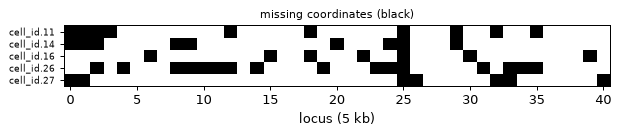

In [2]:
coor = pd.read_csv(SOX2 / "mESC_Sox2_coor_wnan.txt", sep="\t", dtype={"region": str})
ann = pd.read_csv(SOX2 / "mESC_Sox2_ann.txt", sep="\t", dtype={"region": str})
print(f"SnapFISH-IMPUTE table: {coor['haploid'].nunique():,} cells x {coor['region'].nunique()} alleles x "
      f"{coor['pos'].nunique()} loci, {coor['x'].isna().mean():.0%} without coordinates\n")

panel = ann[ann["region"] == "129"]                       # the 41-locus probe panel of the 129 allele
first5 = coor["haploid"].unique()[:5]
t = coor[(coor["region"] == "129") & coor["haploid"].isin(first5)].merge(panel, on=["region", "pos"])
cd = ChromData(t[["x", "y", "z"]].to_numpy(),
               pd.DataFrame({"chrom": t["region"], "start": t["start"], "end": t["end"], "trace_id": t["haploid"]}))
print(cd)
missing = np.isnan(cd.coords[:, 0])
print(f"\n{cd.n_traces} traces x {cd.n_bins} loci = {cd.n_spots} spots; {missing.sum()} without coordinates "
      f"({missing.mean():.0%})")

sp = cd.spots_with_loci()
grid = (pd.DataFrame({"trace": sp["trace_id"].astype(str), "locus": sp["bin_id"], "missing": missing})
        .pivot(index="trace", columns="locus", values="missing"))
fig, ax = plt.subplots(figsize=(7, 1.6))
ax.imshow(grid.to_numpy(), cmap="Greys", aspect="auto", interpolation="nearest")
ax.set_yticks(range(len(grid)), grid.index, fontsize=7); ax.set_xlabel("locus (5 kb)")
ax.set_title("missing coordinates (black)", fontsize=9)
plt.tight_layout(); plt.show()

## 2. Linear and cubic interpolation

Each trace is interpolated on its own, x, y and z separately, as a function of the locus start;
loci before the first / after the last detection are extrapolated (`extrapolate=True`).
Observed coordinates are kept exactly.  The result is a new `ChromData` on the dense
(trace × locus) grid; per-spot tracks and layers are dropped, cell / trace metadata and `uns`
are kept.

In [3]:
lin = impute_coordinates(cd, method="linear")
cub = impute_coordinates(cd, method="cubic")


def by_locus(x):
    """Coordinates indexed by (trace, locus start): imputation may reorder rows."""
    s = x.spots_with_loci()
    return pd.DataFrame(np.asarray(x.coords), columns=list("xyz"),
                        index=pd.MultiIndex.from_arrays([s["trace_id"].astype(str), s["start"]]))


before = by_locus(cd).dropna()
for name, out in [("linear", lin), ("cubic", cub)]:
    after = by_locus(out)
    kept = np.abs(after.loc[before.index].to_numpy() - before.to_numpy()).max()
    print(f"{name:6s}: {out.n_spots} spots, {np.isnan(out.coords[:, 0]).sum()} still missing, "
          f"observed spots moved by at most {kept:.1e} nm")

linear: 205 spots, 0 still missing, observed spots moved by at most 0.0e+00 nm
cubic : 205 spots, 0 still missing, observed spots moved by at most 2.9e-11 nm


## 3. SnapFISH-IMPUTE

SnapFISH-IMPUTE works on pairwise distances rather than positions:

1. densify the traces onto the locus panel and fill a first guess by linear interpolation;
2. turn each trace into its locus–locus distances and normalise every distance by its genomic
   separation (Box-Cox, then mean 0 / variance 1 per separation);
3. iteratively fill each missing distance from the most similar trace that has it
   (similarity = distance between the normalised distance vectors);
4. move the missing loci (L-BFGS, starting from the linear guess) so that the trace's
   distances match the filled ones; observed loci stay fixed.

It needs many traces of the same region: with only five, loci whose distances no similar
trace provides stay NaN.  `n_jobs > 1` runs step 4 in parallel processes.

In [4]:
t0 = time.perf_counter()
snap = impute_coordinates(cd, method="snapfish", max_iter=50, n_jobs=1, verbose=True)
print(f"\n{time.perf_counter() - t0:.1f} s; {np.isnan(snap.coords[:, 0]).sum()} of {snap.n_spots} spots still missing")
after = by_locus(snap)
print(f"observed spots moved by at most {np.abs(after.loc[before.index].to_numpy() - before.to_numpy()).max():.1e} nm")

Input: 147/615 (23.9%) coordinates missing
Dense grid: 205 rows, 49 loci missing coords
Step 1/4: Linear interpolation initialization...
Step 2/4: Computing pairwise distance matrices...


Step 3/4: Iterative similarity-weighted imputation...
  Iteration 1: 1447 NaN values remaining
  Iteration 2: 814 NaN values remaining
  Iteration 3: 200 NaN values remaining
  Iteration 4: 200 NaN values remaining
  Converged: no further improvement
Step 4/4: Recovering 3D coordinates...


Done! Result has 15 coordinates still missing
Note: 15 coordinates remain missing (no reference data)

1.9 s; 5 of 205 spots still missing
observed spots moved by at most 0.0e+00 nm


## 4. Absent rows and the locus panel

Most tracing tables simply omit undetected loci.  All three methods first **densify** each
chromosome onto its locus panel — by default the union of the loci observed in any trace — so
absent rows come back as imputed rows.  A locus that no trace observed is not in that union;
pass the probe panel as `ann=` (columns `chrom` or `region`, `start`, `end`; here the locus
table of section 1) to restore it too.
Here one locus (index 25 in the figure above) was missed in all five traces, so the union
panel has 40 loci and the dense grid 200 rows.

In [5]:
absent = cd[np.flatnonzero(~missing)]                    # drop the NaN rows: loci are now absent
print(f"absent-row input: {absent.n_spots} rows, none NaN")
filled = impute_coordinates(absent, method="linear")
print(f"linear          : {filled.n_spots} rows (dense grid), {np.isnan(filled.coords[:, 0]).sum()} NaN")

# remove one locus from every trace: the observed union no longer contains it ...
dropped_start = int(cd.bins["start"].iloc[20])
no_locus = absent[np.flatnonzero(absent.spots_with_loci()["start"].to_numpy() != dropped_start)]
print(f"without locus {dropped_start:,}: union panel -> {impute_coordinates(no_locus, method='linear').n_spots} rows")
# ... the probe panel (the 129 rows of the locus table) restores it
print("panel:", panel.columns.tolist(), len(panel), "loci")
restored = impute_coordinates(no_locus, method="linear", ann=panel)
print(f"with ann=panel   -> {restored.n_spots} rows, {np.isnan(restored.coords[:, 0]).sum()} NaN")

absent-row input: 156 rows, none NaN
linear          : 200 rows (dense grid), 0 NaN
without locus 34,701,078: union panel -> 195 rows
panel: ['region', 'pos', 'start', 'end'] 41 loci
with ann=panel   -> 205 rows, 0 NaN


## 5. One trace, three methods

The imputed loci (open circles) on one trace, projected on x–y, with the chain drawn in
genomic order.

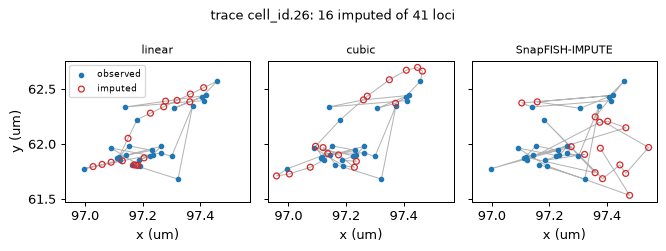

In [6]:
tid = "cell_id.26"
obs = by_locus(cd).loc[tid]
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.8), sharex=True, sharey=True)
for ax, (name, out) in zip(axes, [("linear", lin), ("cubic", cub), ("SnapFISH-IMPUTE", snap)]):
    c = by_locus(out).loc[tid].sort_index() / 1000
    imp = obs["x"].reindex(c.index).isna().to_numpy()
    ax.plot(c["x"], c["y"], "-", color="0.7", lw=0.8, zorder=1)
    ax.scatter(c["x"][~imp], c["y"][~imp], s=12, c="tab:blue", label="observed", zorder=2)
    ax.scatter(c["x"][imp], c["y"][imp], s=22, facecolors="none", edgecolors="tab:red", label="imputed", zorder=3)
    ax.set_title(name, fontsize=9); ax.set_xlabel("x (um)")
axes[0].set_ylabel("y (um)"); axes[0].legend(fontsize=7)
fig.suptitle(f"trace {tid}: {int(imp.sum())} imputed of {len(c)} loci", fontsize=10)
plt.tight_layout(); plt.show()

## 6. How accurate is each method? A hold-out test on real traces

Five traces are too few to judge, so take 300 IMR90 chr21 traces of Bintu et al. 2018
(`uchrom.io.read_bintu_tracing`; undetected segments are absent rows), hide a random 10 % of
the *detected* spots, impute, and compare with the hidden truth:

* **error** — 3-D distance between the imputed and the true position;
* **distance to the neighbouring loci** — imputation should also keep the local chain
  geometry: compare the distance from each hidden locus to the observed loci within 3
  segments (≤ 90 kb) of it, true vs imputed.

In [7]:
from uchrom.io import read_bintu_tracing

bintu = read_bintu_tracing(BINTU, chrom="chr21", start_bp=18_627_714, resolution_bp=30_000)
traces = bintu.spots["trace_id"].unique()[:300]
bintu = bintu[np.flatnonzero(bintu.spots["trace_id"].isin(traces).to_numpy())]
print(f"{bintu.n_traces} traces, {bintu.n_spots:,} detected spots "
      f"({1 - bintu.n_spots / (bintu.n_traces * bintu.n_bins):.1%} of the trace x locus grid undetected)")

rng = np.random.default_rng(0)
hide = rng.choice(bintu.n_spots, size=bintu.n_spots // 10, replace=False)
truth = by_locus(bintu).iloc[hide]
masked = bintu[np.setdiff1d(np.arange(bintu.n_spots), hide)]
full = by_locus(bintu)
per_trace = {t: g.droplevel(0) for t, g in full.groupby(level=0)}
hidden = set(truth.index)
# for each hidden spot: its observed neighbours within 3 segments (90 kb)
neighbours = [(t, s, [n for n in per_trace[t].index if 0 < abs(n - s) <= 90_000 and (t, n) not in hidden])
              for t, s in truth.index]

results, errors = {}, {}
for method, kw in [("linear", {}), ("cubic", {}), ("snapfish", {"max_iter": 50, "n_jobs": 4, "verbose": False})]:
    t0 = time.perf_counter()
    imputed = by_locus(impute_coordinates(masked, method=method, **kw))
    secs = time.perf_counter() - t0
    imp_xyz = imputed.loc[truth.index].to_numpy()
    near_true, near_imp = [], []
    for (t, s, nb), p_true, p_imp in zip(neighbours, truth.to_numpy(), imp_xyz):
        q = per_trace[t].loc[nb].to_numpy()
        near_true += list(np.linalg.norm(q - p_true, axis=1))
        near_imp += list(np.linalg.norm(q - p_imp, axis=1))
    err = np.linalg.norm(imp_xyz - truth.to_numpy(), axis=1)
    errors[method] = err
    results[method] = {"median error (nm)": np.nanmedian(err), "mean error (nm)": np.nanmean(err),
                       "not imputed": int(np.isnan(err).sum()),
                       "median neighbour distance, true (nm)": np.median(near_true),
                       "median neighbour distance, imputed (nm)": np.median(near_imp),
                       "seconds": secs}
print(f"{len(hide):,} hidden spots")
pd.DataFrame(results).round(1)

300 traces, 18,255 detected spots (6.4% of the trace x locus grid undetected)


1,825 hidden spots


,linear,cubic,snapfish
median error (nm),279.1,368.8,436.7
mean error (nm),331.9,523.4,477.2
not imputed,0.0,0.0,0.0
"median neighbour distance, true (nm)",345.9,345.9,345.9
"median neighbour distance, imputed (nm)",258.6,332.7,419.2
seconds,0.1,0.1,76.9


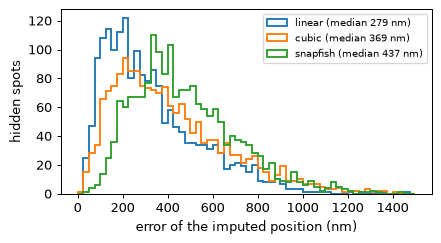

In [8]:
fig, ax = plt.subplots(figsize=(5, 2.8))
bins = np.linspace(0, 1500, 61)
for method, colour in [("linear", "tab:blue"), ("cubic", "tab:orange"), ("snapfish", "tab:green")]:
    ax.hist(errors[method], bins=bins, histtype="step", lw=1.5, color=colour,
            label=f"{method} (median {np.nanmedian(errors[method]):.0f} nm)")
ax.set_xlabel("error of the imputed position (nm)"); ax.set_ylabel("hidden spots"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

On these real traces **linear interpolation places the hidden loci best** (median error
~280 nm, below the ~350 nm median distance between neighbouring segments); cubic splines
overshoot between noisy detections, and SnapFISH-IMPUTE is worse still in median error: it
reproduces the distances of the most similar other trace, not this trace's own path.  The
neighbour distances show a second effect: linear puts a hidden locus on the straight line
between its neighbours and so **shrinks** local distances (~260 vs ~350 nm true), while
SnapFISH-IMPUTE **inflates** them (~420 nm); cubic is closest in this one statistic.  So:
linear for positions (and as a default), and keep in mind that every method biases distance
statistics — compute distance-based features on observed spots where you can.

## 7. Save

Write the imputed objects as stores (here under `tutorials/_out/`).

In [9]:
for name, out in [("linear", lin), ("snapfish", snap)]:
    path = OUT / f"mESC_Sox2_5cells_imputed_{name}.chromdata.zarr"
    out.write(path)
    print("wrote", path)

wrote _out/mESC_Sox2_5cells_imputed_linear.chromdata.zarr


wrote _out/mESC_Sox2_5cells_imputed_snapfish.chromdata.zarr


## Next steps

- `jie_aligner.ipynb` — build traces from raw detections first; `import_fofct.ipynb`,
  `import_pyhim_ecsv.ipynb` — load traced tables.
- Downstream on imputed or observed traces: `tad_calling.ipynb`, `loop_calling.ipynb`,
  `fishnet_domains.ipynb`.
- Compare observed and imputed traces in the web browser:
  `python -m uchrom_browser tutorials/_out/mESC_Sox2_5cells_imputed_linear.chromdata.zarr`.